# Hierarchical model
 reporter : Xi Chen
## Diagnostics

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [13]:

data_file='/Users/zaochen/Documents/BERN02/Exercise/Unsupervised/towelData.csv'

data = pd.read_csv(
    data_file,
    sep=";",
    encoding="latin1"
)

data

,Source,AuthorName,Experiment,Year,Group,Towel.Reuse,Count
0,Goldstein.2008.Ex1,Goldstein et al.,1,2008,Control,Yes,74
1,Goldstein.2008.Ex1,Goldstein et al.,1,2008,Social Norm,Yes,98
2,Goldstein.2008.Ex1,Goldstein et al.,1,2008,Control,No,137
3,Goldstein.2008.Ex1,Goldstein et al.,1,2008,Social Norm,No,124
4,Goldstein.2008.Ex2,Goldstein et al.,2,2008,Control,Yes,103
5,Goldstein.2008.Ex2,Goldstein et al.,2,2008,Social Norm,Yes,587
6,Goldstein.2008.Ex2,Goldstein et al.,2,2008,Control,No,174
7,Goldstein.2008.Ex2,Goldstein et al.,2,2008,Social Norm,No,731
8,Schulz2008.Ex2,Schulz et al.,2,2008,Control,Yes,77
9,Schulz2008.Ex2,Schulz et al.,2,2008,Social Norm,Yes,406


In [ ]:
# input all the yes/no into count[]
count = data.iloc[:, -1]

control_yes = count[::4].to_numpy() #change from pandas Series to array
control_no = count[2::4].to_numpy()
social_yes = count[1::4].to_numpy()
social_no = count[3::4].to_numpy()

In [15]:
print("Control yes:", control_yes)
print("Control no:", control_no)
print("Social yes:", social_yes)
print("Social no:", social_no)

Control yes: [ 74 103  77  82  21 123  28]
Control no: [137 174  58 105   4  24   2]
Social yes: [ 98 587 406 278  21 472 101]
Social no: [124 731 249 277   3 104  31]


In [16]:
control_total = control_yes + control_no
social_total = social_yes + social_no

print("Control total:", control_total)
print("Social total:", social_total)

Control total: [211 277 135 187  25 147  30]
Social total: [ 222 1318  655  555   24  576  132]


In [17]:
control_prop = control_yes / control_total
social_prop = social_yes / social_total

print("Control proportions:", control_prop)
print("Social proportions:", social_prop)

Control proportions: [0.3507109  0.37184116 0.57037037 0.43850267 0.84       0.83673469
 0.93333333]
Social proportions: [0.44144144 0.44537178 0.61984733 0.5009009  0.875      0.81944444
 0.76515152]


Here the the data frame through extracting data.

In [18]:
combined_data = pd.DataFrame({
    "study": np.repeat(np.arange(1, 8), 2),
    "treatment": ["Control", "Social"] * 7,
    "reuse": np.column_stack((control_yes, social_yes)).flatten(),
    "total": np.column_stack((control_total, social_total)).flatten()
})

combined_data["proportion"] = (
    combined_data["reuse"] / combined_data["total"]
)

combined_data

,study,treatment,reuse,total,proportion
0,1,Control,74,211,0.350711
1,1,Social,98,222,0.441441
2,2,Control,103,277,0.371841
3,2,Social,587,1318,0.445372
4,3,Control,77,135,0.570370
5,3,Social,406,655,0.619847
6,4,Control,82,187,0.438503
7,4,Social,278,555,0.500901
8,5,Control,21,25,0.840000
9,5,Social,21,24,0.875000


For each study, select its Control and socail observations and connect their towel-reuse proportions with a line to visualize the treatment change.

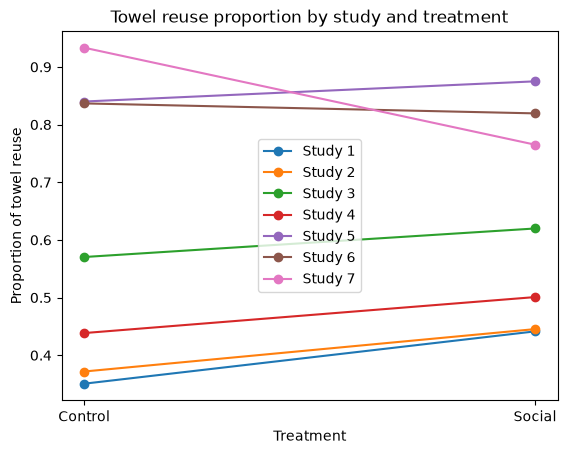

In [19]:
for study in range(1, 8):
    subset = combined_data[combined_data["study"] == study]

    plt.plot(
        subset["treatment"],
        subset["proportion"],
        marker="o",
        label=f"Study {study}"
    )

plt.xlabel("Treatment")
plt.ylabel("Proportion of towel reuse")
plt.title("Towel reuse proportion by study and treatment")
plt.legend()
plt.show()

It is easy to see that a higher towel-reuse proportion in the socail-norm group. But all the baseline reuse rate and the apparent treatment are different from studies.

In [20]:
combined_data["study"] = combined_data["study"].astype("category") # consider as category insraed of number
combined_data["treatment"] = combined_data["treatment"].astype("category")

combined_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   study       14 non-null     category
 1   treatment   14 non-null     category
 2   reuse       14 non-null     int64   
 3   total       14 non-null     int64   
 4   proportion  14 non-null     float64 
dtypes: category(2), float64(1), int64(2)
memory usage: 568.0 bytes


In [21]:
import bambi as bmb
import arviz as az

The number of towel reuses using a binomial distribution and allow the baseline towel-reuse probability to vary between studies. This indicates considerable between-study heterogeneity.
We hypothesize two 
$$Y_{ij} \sim \text{Binomial}(n_{ij}, p_{ij})$$
and
$$\text{logit}(p_{ij}) = \beta_0 + \beta_1 \text{Treatment}_{ij} + u_j$$
where
$$u_j \sim N(0, \sigma_{\text{study}})$$


In [ ]:
model = bmb.Model(
    "p(reuse, total) ~ treatment + (1|study)", #+ (1|study) is the random intercept
    combined_data,
    family="binomial"
)

model

       Formula: p(reuse, total) ~ treatment + (1|study)
        Family: binomial
          Link: p = logit
  Observations: 14
        Priors: 
    target = p
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 1.5)
            treatment ~ Normal(mu: 0.0, sigma: 1.0)
        
        Group-level effects
            1|study ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 2.5495))

In [26]:
idata = model.fit(
    draws=2000,
    tune=2000,
    chains=4,
    random_seed=42,
    target_accept=0.95
)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [Intercept, treatment, 1|study_sigma, 1|study_offset]


/Users/zaochen/miniforge3/envs/bern02/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.
There were 105 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In the initial fit, the sampler produced 92 divergences after tuning and the R-hat statistic was larger than 1.01 for some parameters. These diagnostics indicated that the posterior was not sampled reliably.

To improve the sampling, I increased `target_accept` to 0.95, which makes the NUTS sampler use more conservative sampling steps. However, the new fit still produced 105 divergences. In addition, some parameters had R-hat values above 1.01 and low effective sample sizes.

Therefore, increasing `target_accept` alone did not solve the sampling problem. The current sampling is not sufficiently reliable for final posterior inference.

In [28]:
summary = az.summary(
    idata,
)

summary

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,0.5,0.6,-0.2,1.3,297,167,1.02,0.06,0.12
treatment[Social],0.211,0.079,0.084,0.33,3263,3458,1.00,0.0014,0.001
1|study_sigma,1.2,0.6,0.64,2.3,296,157,1.02,0.065,0.12
1|study[1],-1,0.6,-1.8,-0.3,290,167,1.01,0.061,0.12
1|study[2],-0.9,0.6,-1.7,-0.24,297,166,1.02,0.061,0.12
1|study[3],-0.2,0.6,-0.99,0.48,287,163,1.02,0.062,0.12
1|study[4],-0.7,0.6,-1.5,-0.017,293,160,1.02,0.062,0.12
1|study[5],1.1,0.6,0.14,2,294,176,1.01,0.054,0.084
1|study[6],0.9,0.6,0.098,1.6,302,150,1.01,0.061,0.12
1|study[7],0.7,0.6,-0.15,1.4,294,164,1.02,0.062,0.12


The summary shows that the treatmnet coefficient itself has good sampling dignostics, with R-hat about 1.00 in a relatively large effective sample size. In contrast, the intercept, the study-level standard deviation, and several
study-specific effects have R-hat values around 1.01–1.02. so we can guess the sampling problem is mainly related to the hierarchical study-level component.



The default prior for the standard deviation of the study-specific intercepts
was relatively broad on the logit scale. So we try Half-Normal(1) prior for the study-level
standard deviation.

In [29]:
study_prior = bmb.Prior(
    "Normal",
    mu=0,
    sigma=bmb.Prior("HalfNormal", sigma=1)
)

In [30]:
model2 = bmb.Model(
    "p(reuse, total) ~ treatment + (1|study)",
    combined_data,
    family="binomial",
    priors={"1|study": study_prior}
)

model2

       Formula: p(reuse, total) ~ treatment + (1|study)
        Family: binomial
          Link: p = logit
  Observations: 14
        Priors: 
    target = p
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 1.5)
            treatment ~ Normal(mu: 0.0, sigma: 1.0)
        
        Group-level effects
            1|study ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 1.0))

In [31]:
idata2 = model2.fit(
    draws=2000,
    tune=2000,
    chains=4,
    random_seed=42,
    target_accept=0.95
)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [Intercept, treatment, 1|study_sigma, 1|study_offset]


/Users/zaochen/miniforge3/envs/bern02/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Unlike the previous fit, the sampler reported no divergences and no warnings concerning R-hat or effective sample size. 

In [32]:
summary2 = az.summary(idata2)
summary2

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,0.43,0.38,-0.16,1,1416,1973,1.00,0.01,0.0089
treatment[Social],0.211,0.079,0.085,0.34,4242,4008,1.00,0.0012,0.00098
1|study_sigma,0.99,0.3,0.62,1.5,1476,2383,1.00,0.0079,0.008
1|study[1],-0.94,0.38,-1.5,-0.35,1427,2220,1.00,0.01,0.0085
1|study[2],-0.87,0.38,-1.5,-0.28,1383,2125,1.00,0.01,0.0088
1|study[3],-0.15,0.38,-0.73,0.43,1389,2112,1.00,0.01,0.0089
1|study[4],-0.64,0.38,-1.2,-0.053,1393,2144,1.00,0.01,0.0088
1|study[5],1.1,0.49,0.36,1.9,2294,3249,1.00,0.01,0.0069
1|study[6],0.94,0.38,0.35,1.5,1421,2100,1.00,0.01,0.0087
1|study[7],0.74,0.41,0.1,1.4,1595,2318,1.00,0.01,0.0082


This revised model showed satisfactory convergence. All R-hat value were 1.00, and no divergences were found.

The posterior mean of the social treatment coefficient was 0.21 on the log-odd scale, as it is above 0, so we suggest towel-reuse odds under the socail treatment is higher.

There is substantial variation in baseline towel-reuse behaviour beween studies as THe estimated study-level standard deviation was 0.99.

In [34]:
treatment_samples = idata2.posterior["treatment"].values.flatten()

mean_treatment = np.mean(treatment_samples)

lower_90 = np.quantile(treatment_samples, 0.05)
upper_90 = np.quantile(treatment_samples, 0.95)

print("Posterior mean:", mean_treatment)
print("90% probability interval:", lower_90, upper_90)

Posterior mean: 0.21115755027251668
90% probability interval: 0.08043990237663581 0.34016782214380514


Socail treatment effect lies between about 0.08 and 0.34 with 90% of the posterior probability.

In [35]:
prob_positive = np.mean(treatment_samples > 0)

print("P(treatment effect > 0 | data) =", prob_positive)

P(treatment effect > 0 | data) = 0.9965


The entire interval is above zero, and the posterior probability of a positive treatment effect was 0.9965.


In [36]:
odds_ratio_samples = np.exp(treatment_samples)

mean_or = np.mean(odds_ratio_samples)
lower_or = np.quantile(odds_ratio_samples, 0.05)
upper_or = np.quantile(odds_ratio_samples, 0.95)

print("Posterior mean odds ratio:", mean_or)
print("90% probability interval:", lower_or, upper_or)

Posterior mean odds ratio: 1.2389457276636358
90% probability interval: 1.0837637130942115 1.4051833930100799


the posterior mean was 1.24, with a 90% probability interval from 1.08 to 1.41. This means that the odds of towel reuse under the Social treatment were estimated to be about 24% higher than under the Control condition.

## Hypothesis testing
The effectiveness of the Social intervention was tested using the treatment coefficient, $\beta_1$, in the hierarchical model.
The hypotheses were formulated as:
$$
H_0: \beta_1 \leq 0
$$
$$
H_1: \beta_1 > 0
$$

In [40]:
prob_nonpositive = np.mean(treatment_samples <= 0)

print("P(H1 | data) =", prob_positive)
print("P(H0 | data) =", prob_nonpositive)

P(H1 | data) = 0.9965
P(H0 | data) = 0.0035


Therefore, the posterior distribution provides strong evidence that the Social intervention has a positive effect on towel reuse.

## conclusion
The Social treatment had a positive effect on towel reuse. The posterior meanof the treatment coefficient was 0.211, with a 90% probability interval of [0.080, 0.340].
